# Exploring Player Plays

One row per prospect per play they were on the field for. All data is taken from [here](https://www.kaggle.com/competitions/nfl-big-data-bowl-2027/data). Most of the columns are only filled for the relevant role (e.g. `route_ran` for receivers, `pressure_allowed` for blockers).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

## player_play.csv

In [2]:
df = pd.read_csv("../data/player_play.csv")
df.head().style.format(precision=2).set_caption("First Rows")

,game_id,play_id,team_abbr,nfl_id,lined_up_position,play_description,quarter,down,yards_to_go,possession_team,yardline_side,yardline_number,game_clock,pre_snap_home_score,pre_snap_visitor_score,play_direction,pre_snap_home_team_win_probability,pre_snap_visitor_team_win_probability,home_team_win_probability_added,visitor_team_win_probility_added,expected_points_added,expected_points,offense_formation,receiver_alignment,pass_result,pass_length,play_nullified_by_penalty,penalty_yards,pre_penalty_yards_gained,yards_gained,team_coverage_man_zone,team_coverage_type,in_motion_at_ball_snap,target,rec_yards,rush_yards,yards_after_catch,fumble,fumble_lost,route_ran,separation_at_pass_forward,cushion,expected_yards_after_catch,dropback_duration,extended_sack_allowed,pass_rushers_encountered,peak_pressure_probability_allowed,pressure_allowed,sack_allowed,time_to_pressure_allowed,quick_pressure,unblocked_pressure,blitzing,player_get_off,sack,tackle,assist,caused_forced_fumble,recovered_fumble,tackle_for_loss,time_to_pressure,time_to_qb_hurry,coverage_assignment,coverage_assignment_at_snap
0,2025111610,2279,BAL,57183,T,(8:42) (Shotgun) L.Jackson pass incomplete deep left to D.Hopkins.,3,1,10,BAL,BAL,45,08:42,16,10,right,0.49,0.51,0.03,-0.03,-0.51,2.72,SHOTGUN,3x1,I,22.00,N,nan,0,0,MAN_COVERAGE,COVER_1_MAN,False,False,nan,nan,nan,nan,nan,nan,nan,nan,nan,2.08,0.00,1.00,0.15,False,0.00,nan,nan,nan,False,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
1,2026011701,1626,SF,58248,INTERIOR_LINE,(3:48) (Shotgun) K.Walker left end to SEA 28 for 5 yards (S.Okuayinonu; M.Sigle).,2,2,7,SEA,SEA,23,03:48,17,6,left,0.93,0.07,-0.00,0.00,-0.05,0.36,SHOTGUN,2x1,nan,nan,N,nan,5,5,ZONE_COVERAGE,COVER_2_ZONE,nan,False,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
2,2025101900,2838,LAR,57140,EDGE,(7:01) C.Van Lanen reported in as eligible. T.Lawrence scrambles left tackle pushed ob at LA 30 for 14 yards (K.Curl).,3,2,2,JAX,LAR,44,07:01,0,21,left,0.05,0.95,0.01,-0.01,0.93,3.31,SINGLEBACK,3x1,R,nan,N,nan,14,14,ZONE_COVERAGE,COVER_3_ZONE,nan,False,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,False,True,0.91,0.00,nan,nan,nan,nan,nan,nan,nan,NO_ASSIGNMENT,NO_ASSIGNMENT
3,2025111300,2628,NYJ,58209,T,(4:05) I.Williams left end to NE 22 for 4 yards (J.Gibbens; C.Woodson).,3,1,10,NYJ,NE,26,04:05,21,7,right,0.96,0.04,0.00,-0.00,-0.11,4.44,SINGLEBACK,3x1,nan,nan,N,nan,4,4,ZONE_COVERAGE,COVER_6_ZONE,False,False,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
4,2025121406,2653,NYG,57191,OLB,"(10:08) (No Huddle, Shotgun) M.Mariota scrambles right tackle to WAS 36 for 7 yards (A.Phillips).",3,2,10,WAS,WAS,29,10:08,14,22,left,0.20,0.80,0.00,-0.00,0.09,1.06,PISTOL,3x1,R,nan,N,nan,7,7,ZONE_COVERAGE,COVER_2_ZONE,nan,False,nan,nan,nan,nan,nan,nan,nan,7.24,nan,nan,nan,nan,nan,nan,nan,nan,nan,False,False,nan,0.00,1.00,0.00,0.00,nan,False,nan,nan,HOOK_CURL_LEFT,CURL_FLAT_LEFT


In [3]:
print(len(df)) # total number of player-plays in dataset
print(df["nfl_id"].nunique()) # number of distinct players
print(df["game_id"].nunique()) # number of distinct games

314197
497
1001


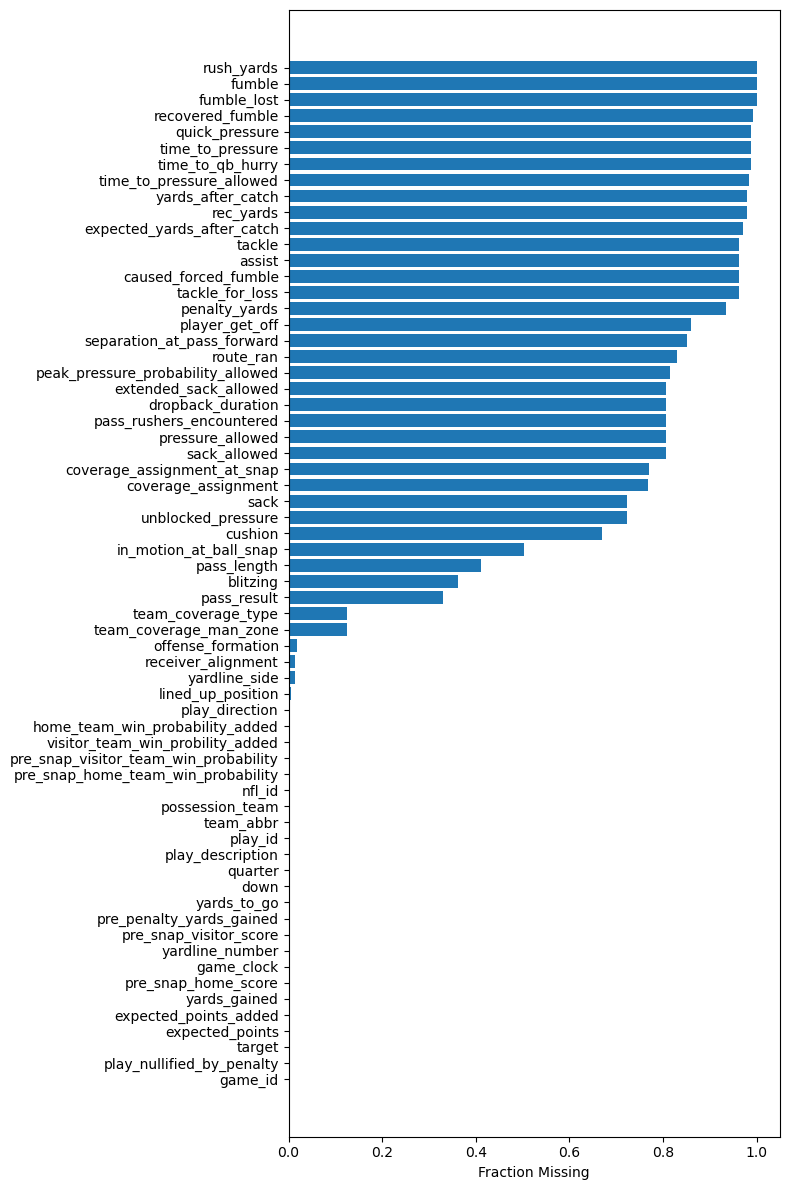

In [4]:
missing = df.isna().mean().sort_values()

fig, ax = plt.subplots(figsize=(8,12))
ax.barh(missing.index, missing.values)
ax.set_xlabel("Fraction Missing")
plt.tight_layout()
plt.show()

In [5]:
positions = pd.read_csv("../data/combine_results.csv", usecols=["nfl_id", "combine_position"])
df = df.merge(positions, on="nfl_id", how="left")

masks = {
    "TE": df["combine_position"] == "TE",
    "DB": df["combine_position"] == "DB",
    "WR": df["combine_position"] == "WR",
    "DL": df["combine_position"] == "DL",
    "OL": df["combine_position"] == "OL",
}

### Plays per Player

In [6]:
plays_per_player = df.groupby("nfl_id").size().rename("plays").reset_index()
plays_per_player = plays_per_player.merge(positions, on="nfl_id", how="left")

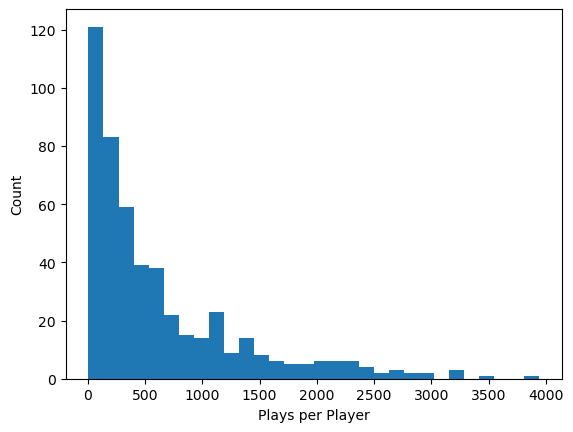

In [7]:
plt.hist(plays_per_player["plays"].dropna(), bins=30)
plt.xlabel("Plays per Player")
plt.ylabel("Count");

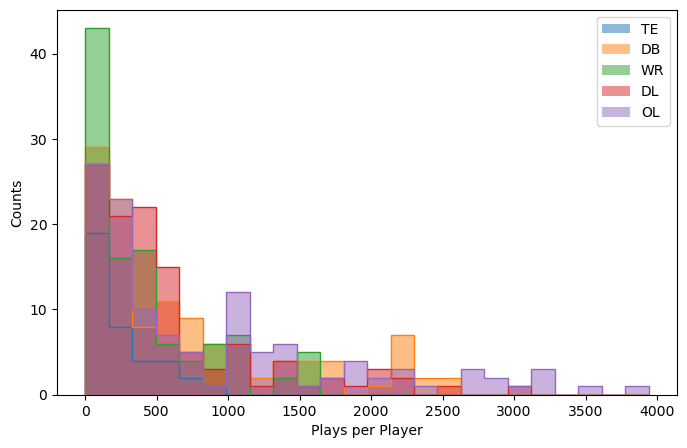

In [8]:
fig, ax = plt.subplots(figsize=(8,5))
bins = np.linspace(0, plays_per_player["plays"].max(), 25)
for i, name in enumerate(masks):
    m = plays_per_player["combine_position"] == name
    ax.hist(plays_per_player.loc[m, "plays"], bins=bins, histtype="step", color=f"C{i}")
    ax.hist(plays_per_player.loc[m, "plays"], bins=bins, histtype="stepfilled", label=name, color=f"C{i}", alpha=0.5)
ax.set_xlabel("Plays per Player")
ax.set_ylabel("Counts")
ax.legend()
plt.show()

### Play Context

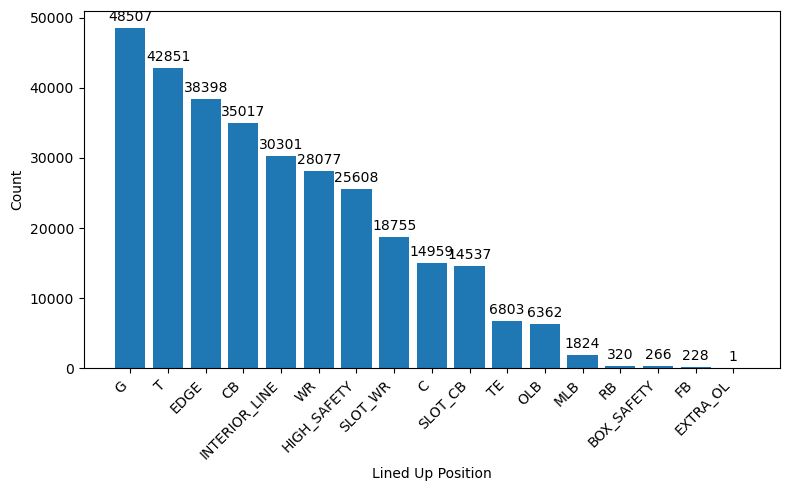

In [9]:
counts = df["lined_up_position"].value_counts()

fig, ax = plt.subplots(figsize=(8,5))
bars = ax.bar(counts.index.astype(str), counts.values)
ax.bar_label(bars, padding=3)

ax.set_xlabel("Lined Up Position")
ax.set_ylabel("Count")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [10]:
pd.crosstab(df["lined_up_position"], df["combine_position"])

combine_position,DB,DL,OL,TE,WR
lined_up_position,,,,,
BOX_SAFETY,266,0,0,0,0
C,0,0,14959,0,0
CB,34980,36,1,0,0
EDGE,1567,36831,0,0,0
EXTRA_OL,0,0,1,0,0
FB,5,0,46,129,48
G,0,0,48507,0,0
HIGH_SAFETY,25598,0,10,0,0
INTERIOR_LINE,129,30172,0,0,0


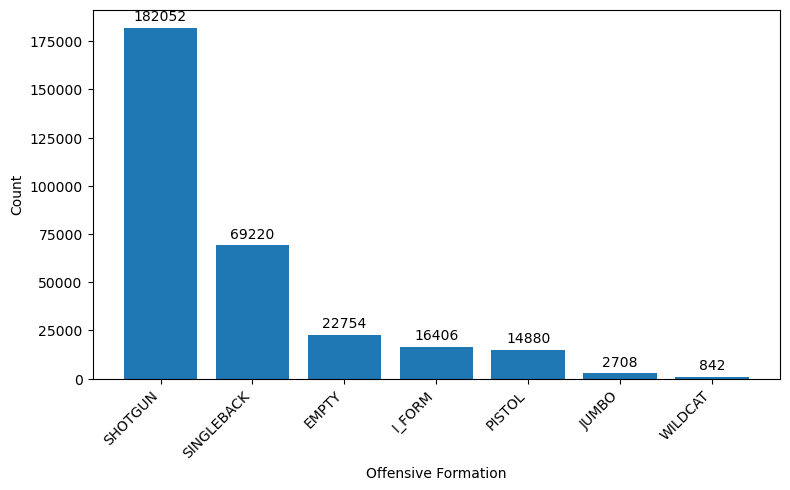

In [11]:
counts = df["offense_formation"].value_counts()

fig, ax = plt.subplots(figsize=(8,5))
bars = ax.bar(counts.index.astype(str), counts.values)
ax.bar_label(bars, padding=3)

ax.set_xlabel("Offensive Formation")
ax.set_ylabel("Count")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

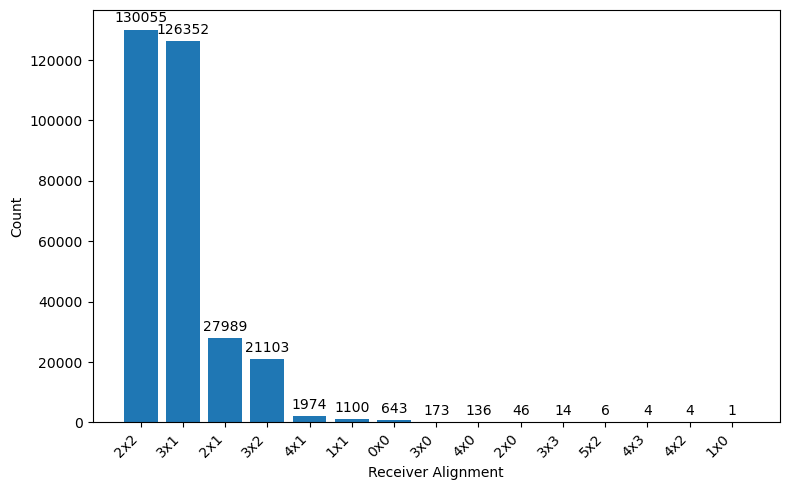

In [12]:
counts = df["receiver_alignment"].value_counts()

fig, ax = plt.subplots(figsize=(8,5))
bars = ax.bar(counts.index.astype(str), counts.values)
ax.bar_label(bars, padding=3)

ax.set_xlabel("Receiver Alignment")
ax.set_ylabel("Count")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

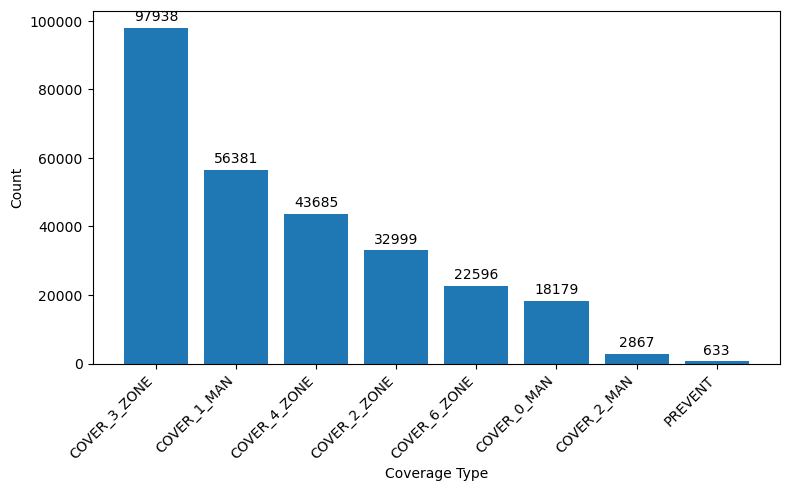

In [13]:
counts = df["team_coverage_type"].value_counts()

fig, ax = plt.subplots(figsize=(8,5))
bars = ax.bar(counts.index.astype(str), counts.values)
ax.bar_label(bars, padding=3)

ax.set_xlabel("Coverage Type")
ax.set_ylabel("Count")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

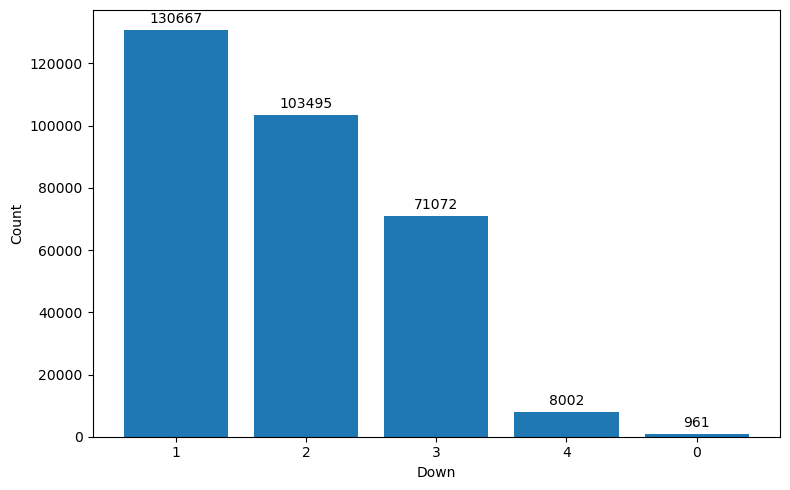

In [14]:
counts = df["down"].value_counts()

fig, ax = plt.subplots(figsize=(8,5))
bars = ax.bar(counts.index.astype(str), counts.values)
ax.bar_label(bars, padding=3)

ax.set_xlabel("Down")
ax.set_ylabel("Count")
plt.tight_layout()
plt.show()

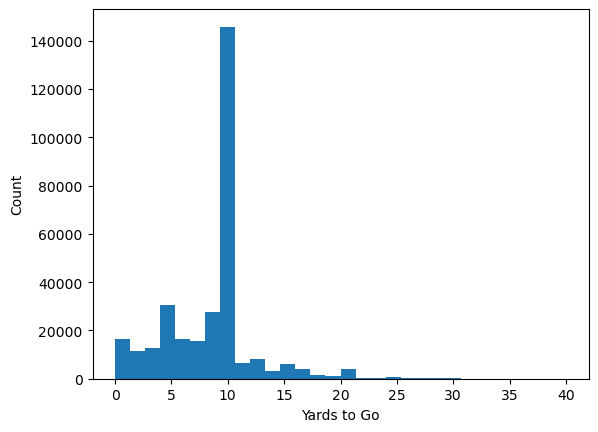

In [15]:
plt.hist(df["yards_to_go"].dropna(), bins=30)
plt.xlabel("Yards to Go")
plt.ylabel("Count");

### Play Outcomes

Note that these are play-level values, so they're repeated for every prospect on the field for that play.

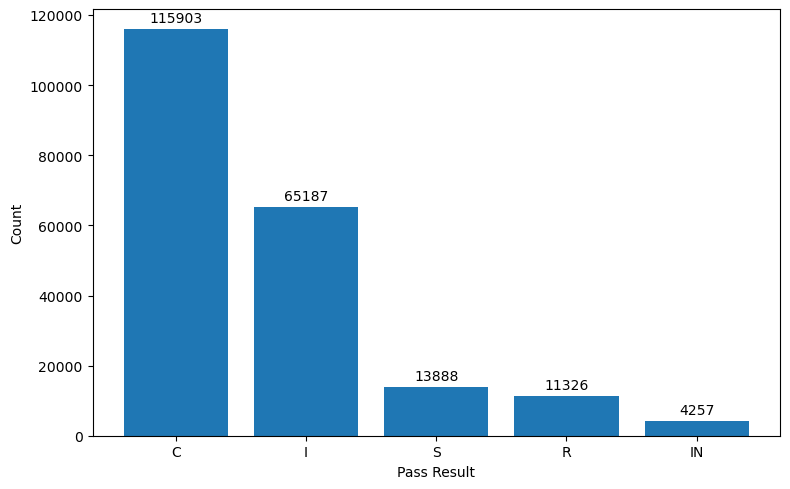

In [16]:
counts = df["pass_result"].value_counts()

fig, ax = plt.subplots(figsize=(8,5))
bars = ax.bar(counts.index.astype(str), counts.values)
ax.bar_label(bars, padding=3)

ax.set_xlabel("Pass Result")
ax.set_ylabel("Count")
plt.tight_layout()
plt.show()

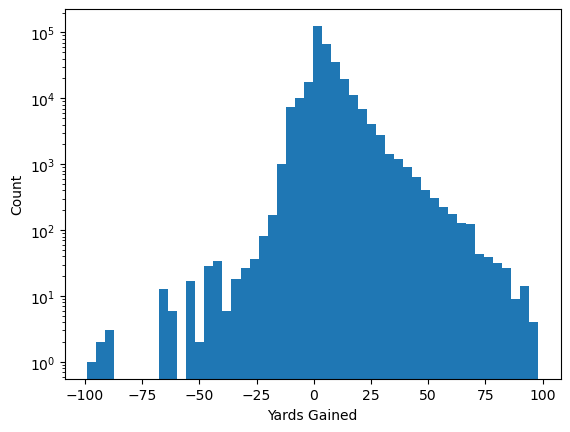

In [17]:
plt.hist(df["yards_gained"].dropna(), bins=50)
plt.xlabel("Yards Gained")
plt.ylabel("Count")
plt.yscale("log");

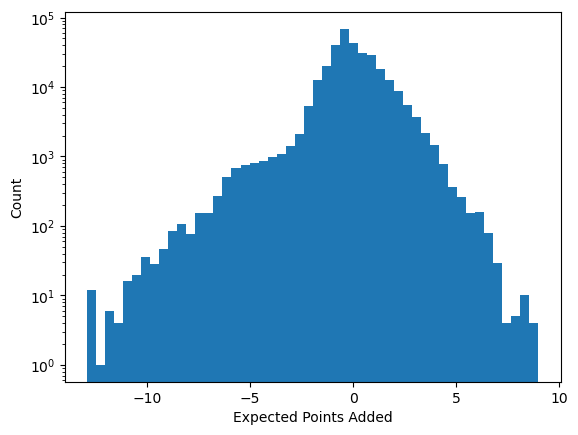

In [18]:
plt.hist(df["expected_points_added"].dropna(), bins=50)
plt.xlabel("Expected Points Added")
plt.ylabel("Count")
plt.yscale("log");

### Receiving (WR / TE)

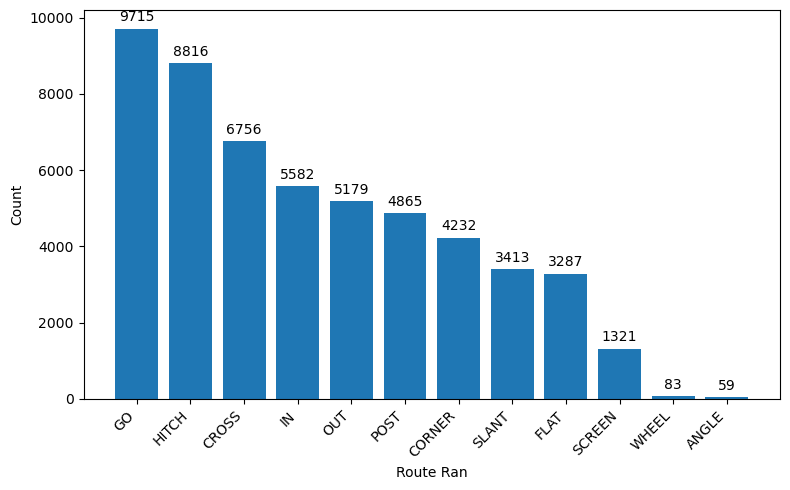

In [19]:
counts = df["route_ran"].value_counts()

fig, ax = plt.subplots(figsize=(8,5))
bars = ax.bar(counts.index.astype(str), counts.values)
ax.bar_label(bars, padding=3)

ax.set_xlabel("Route Ran")
ax.set_ylabel("Count")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [20]:
routes = df[df["route_ran"].notna()]
print(routes["target"].mean()) # fraction of routes that were targeted
print(routes.groupby("combine_position")["target"].mean())

0.18462519696856006
combine_position
DB    0.181818
OL    0.333333
TE    0.167545
WR    0.188471
Name: target, dtype: float64


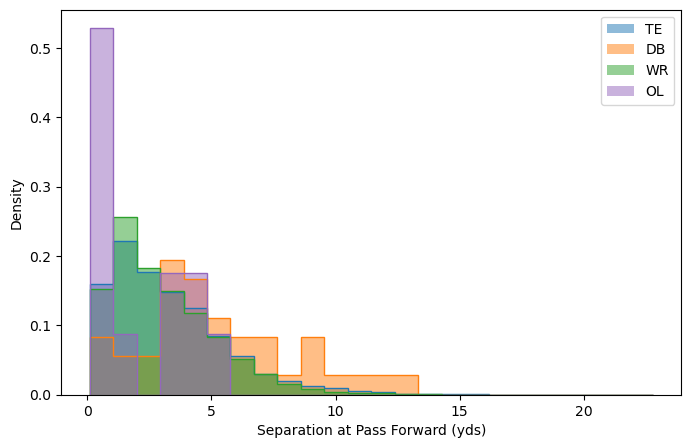

In [21]:
bins = np.linspace(df["separation_at_pass_forward"].min(), df["separation_at_pass_forward"].max(), 25)

fig, ax = plt.subplots(figsize=(8,5))
for i, (name, m) in enumerate(masks.items()):
    if df.loc[m, "separation_at_pass_forward"].isna().all():
        continue
    color = f"C{i}"
    ax.hist(df.loc[m, "separation_at_pass_forward"], bins=bins, histtype="step", color=color, density=True)
    ax.hist(df.loc[m, "separation_at_pass_forward"], bins=bins, histtype="stepfilled", label=name, color=color, alpha=0.5, density=True)

ax.set_xlabel("Separation at Pass Forward (yds)")
ax.set_ylabel("Density")
ax.legend()
plt.show()

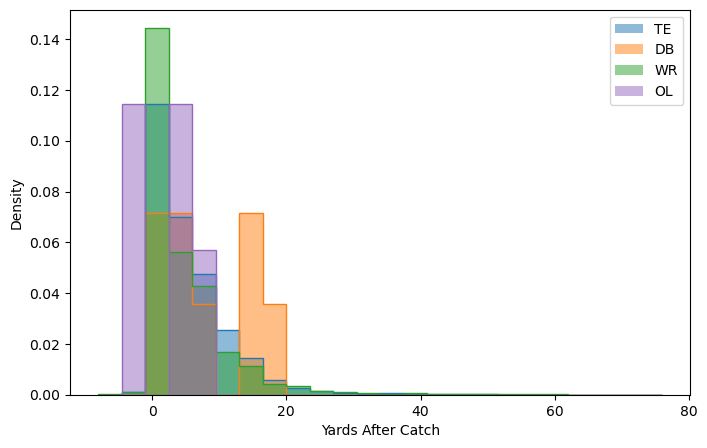

In [22]:
bins = np.linspace(df["yards_after_catch"].min(), df["yards_after_catch"].max(), 25)

fig, ax = plt.subplots(figsize=(8,5))
for i, (name, m) in enumerate(masks.items()):
    if df.loc[m, "yards_after_catch"].isna().all():
        continue
    color = f"C{i}"
    ax.hist(df.loc[m, "yards_after_catch"], bins=bins, histtype="step", color=color, density=True)
    ax.hist(df.loc[m, "yards_after_catch"], bins=bins, histtype="stepfilled", label=name, color=color, alpha=0.5, density=True)

ax.set_xlabel("Yards After Catch")
ax.set_ylabel("Density")
ax.legend()
plt.show()

### Pass Blocking (OL / TE)

In [23]:
blocks = df[df["pressure_allowed"].notna()]
print(len(blocks)) # pass blocking snaps
print(blocks["pressure_allowed"].astype(bool).groupby(blocks["combine_position"]).mean()) # pressure rate allowed

60803
combine_position
DB    0.000000
OL    0.081929
TE    0.067460
WR    0.082569
Name: pressure_allowed, dtype: float64


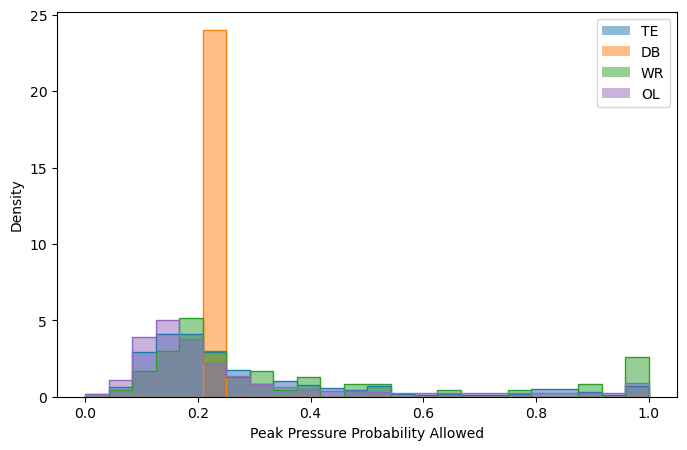

In [24]:
bins = np.linspace(df["peak_pressure_probability_allowed"].min(), df["peak_pressure_probability_allowed"].max(), 25)

fig, ax = plt.subplots(figsize=(8,5))
for i, (name, m) in enumerate(masks.items()):
    if df.loc[m, "peak_pressure_probability_allowed"].isna().all():
        continue
    color = f"C{i}"
    ax.hist(df.loc[m, "peak_pressure_probability_allowed"], bins=bins, histtype="step", color=color, density=True)
    ax.hist(df.loc[m, "peak_pressure_probability_allowed"], bins=bins, histtype="stepfilled", label=name, color=color, alpha=0.5, density=True)

ax.set_xlabel("Peak Pressure Probability Allowed")
ax.set_ylabel("Density")
ax.legend()
plt.show()

### Pass Rush and Defense (DL / DB)

In [25]:
print(df.groupby("combine_position")["blitzing"].apply(lambda s: s.dropna().astype(bool).mean())) # fraction of snaps rushing

combine_position
DB    0.025730
DL    0.949711
OL    0.000000
TE    0.000000
WR    0.000000
Name: blitzing, dtype: float64


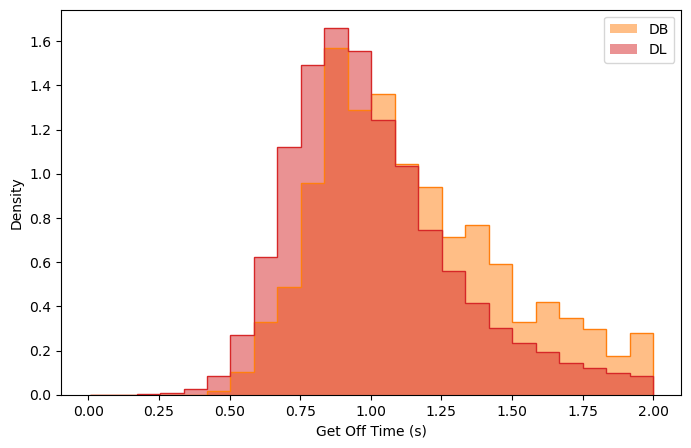

In [26]:
bins = np.linspace(df["player_get_off"].min(), df["player_get_off"].max(), 25)

fig, ax = plt.subplots(figsize=(8,5))
for i, (name, m) in enumerate(masks.items()):
    if df.loc[m, "player_get_off"].isna().all():
        continue
    color = f"C{i}"
    ax.hist(df.loc[m, "player_get_off"], bins=bins, histtype="step", color=color, density=True)
    ax.hist(df.loc[m, "player_get_off"], bins=bins, histtype="stepfilled", label=name, color=color, alpha=0.5, density=True)

ax.set_xlabel("Get Off Time (s)")
ax.set_ylabel("Density")
ax.legend()
plt.show()

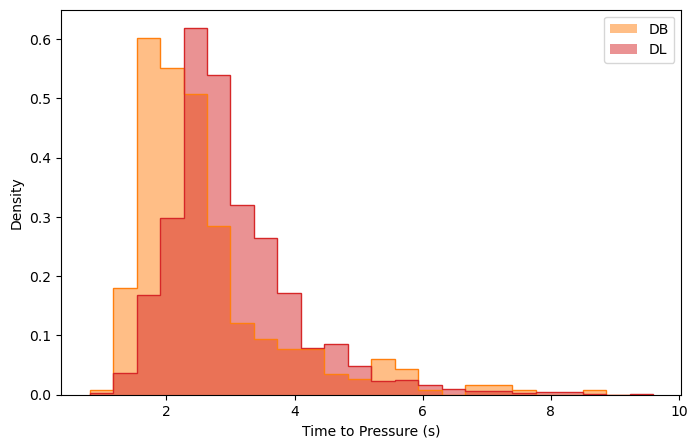

In [27]:
bins = np.linspace(df["time_to_pressure"].min(), df["time_to_pressure"].max(), 25)

fig, ax = plt.subplots(figsize=(8,5))
for i, (name, m) in enumerate(masks.items()):
    if df.loc[m, "time_to_pressure"].isna().all():
        continue
    color = f"C{i}"
    ax.hist(df.loc[m, "time_to_pressure"], bins=bins, histtype="step", color=color, density=True)
    ax.hist(df.loc[m, "time_to_pressure"], bins=bins, histtype="stepfilled", label=name, color=color, alpha=0.5, density=True)

ax.set_xlabel("Time to Pressure (s)")
ax.set_ylabel("Density")
ax.legend()
plt.show()

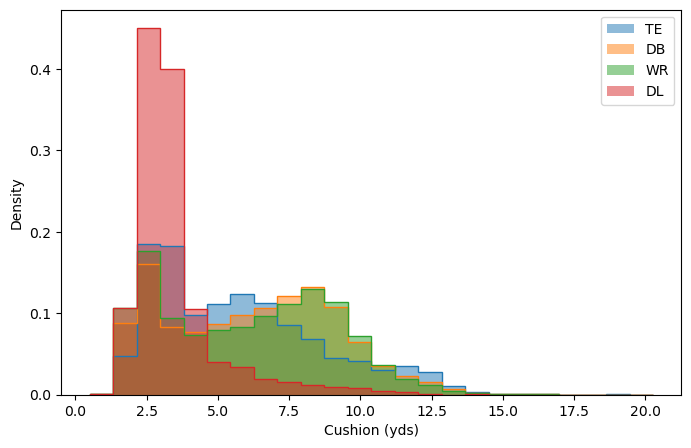

In [28]:
bins = np.linspace(df["cushion"].min(), df["cushion"].max(), 25)

fig, ax = plt.subplots(figsize=(8,5))
for i, (name, m) in enumerate(masks.items()):
    if df.loc[m, "cushion"].isna().all():
        continue
    color = f"C{i}"
    ax.hist(df.loc[m, "cushion"], bins=bins, histtype="step", color=color, density=True)
    ax.hist(df.loc[m, "cushion"], bins=bins, histtype="stepfilled", label=name, color=color, alpha=0.5, density=True)

ax.set_xlabel("Cushion (yds)")
ax.set_ylabel("Density")
ax.legend()
plt.show()

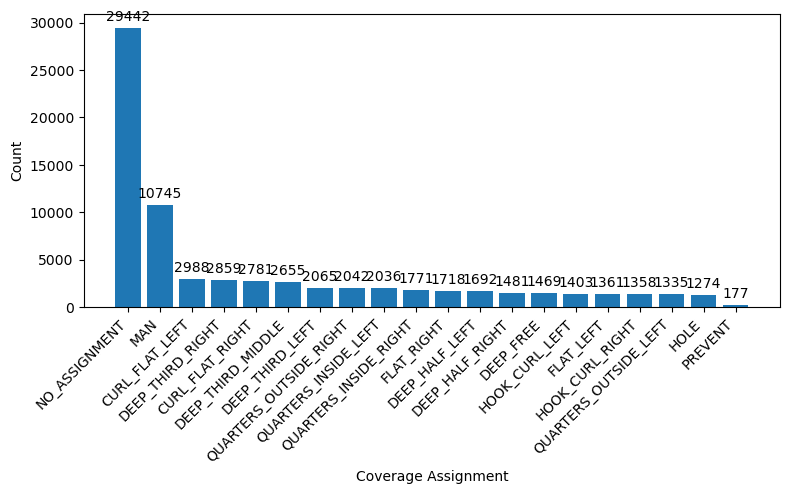

In [29]:
counts = df["coverage_assignment"].value_counts().head(20)

fig, ax = plt.subplots(figsize=(8,5))
bars = ax.bar(counts.index.astype(str), counts.values)
ax.bar_label(bars, padding=3)

ax.set_xlabel("Coverage Assignment")
ax.set_ylabel("Count")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [30]:
tackling = df.groupby("nfl_id")[["tackle", "assist", "sack"]].sum().merge(positions, on="nfl_id")
tackling.groupby("combine_position")[["tackle", "assist", "sack"]].sum()

,tackle,assist,sack
combine_position,,,
DB,4918.0,2418.0,41.0
DL,2278.0,2076.0,454.0
OL,37.0,12.0,0.0
TE,21.0,4.0,0.0
WR,123.0,7.0,0.0
